In [1]:
import sys
print(sys.version)
print(sys.executable)

3.11.16 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:36:16) [MSC v.1942 64 bit (AMD64)]
C:\Users\seanf\anaconda3\envs\elisa\python.exe


In [40]:
from elisa import BinarySystem
from elisa import Star
from astropy import units as u
import matplotlib.pyplot as plt
import os
import elisa
print(elisa.__version__)
cwd = os.getcwd()

0.6.2


In [4]:
primary = Star(
    mass = 2.3 * u.solMass, # mass in solar masses
    surface_potential = 3.3, # tl:dr, size/shape of star, the Roche lobe
    # a dimensionless Roche potential, the effective potential of a star in a binary system, accounting for the gravitational potential  
    # of both stars and the centrifugal potential of the orbiting bodies.
    # the contour line at which the potential is equal to this value is the Roche Lobe.
    
    synchronicity = 1, # ratio between star's rotational period and orbital period
    t_eff = 8000 * u.K, # effective temperature
    # optionals such as albedo, metallicity, gravity darkening (stars being brighter at the poles due to rotation expanding the star at equator)    
)

secondary = Star(
    mass = 0.6 * u.solMass,
    surface_potential = 4.7,
    synchronicity = 1,
    t_eff = 4500 * u.K
)

In [5]:
bs = BinarySystem(
    primary=primary,
    secondary=secondary,
    argument_of_periastron = 46 * u.deg, # the argument of periapsis, but specifically for when the body is a star
    gamma = 29 * u.km / u.s, # the speed at which the entire system is moving through the galaxy, in km/s
    period = 2.6 * u.d, # the orbital period, in days
    eccentricity = 0.0,
    inclination = 73 * u.deg,
    primary_minimum_time = 2440000.0000 * u.d, # the time (in days) at which the light curve is minimum
    phase_shift = 0,
    distance = 178 * u.pc
)

2026-09-23 12:10:02,129 - 11396 - binary_system.system - INFO: initialising object BinarySystem
2026-09-23 12:10:02,240 - 11396 - binary_system.system - INFO: setting discretization factor of secondary component to 8.00 according to discretization factor of the companion.


In [6]:
from elisa import Observer
from elisa import settings

o = Observer(passband=[  # defining passbands at which calculate a light curve
#     'Generic.Bessell.U',
    'Generic.Bessell.B',
    'Generic.Bessell.V',
    'Generic.Bessell.R',
    'Generic.Bessell.I',
                      ],
             system=bs)  # specifying the binary system to use in light curve synthesis



2026-09-23 12:10:02,256 - 11396 - observer.observer - INFO: initialising Observer instance


In [7]:
#settings.PASSBANDS

In [8]:
phases, fluxes = o.observe.lc( # fluxes contains synthetic light curve data for each passband specified in Observer
    from_phase=0,
    to_phase=1,
    phase_step=0.01,
    # normalize=True
)

2026-09-23 12:10:02,336 - 11396 - observer.observer - INFO: observation is running
2026-09-23 12:10:04,025 - 11396 - elisa.atm - INFO: time 0.001531839370727539
2026-09-23 12:10:04,030 - 11396 - elisa.atm - INFO: time 0.0015139579772949219
2026-09-23 12:10:04,035 - 11396 - elisa.atm - INFO: time 0.003154754638671875
2026-09-23 12:10:04,038 - 11396 - elisa.atm - INFO: time 0.0016939640045166016
2026-09-23 12:10:04,154 - 11396 - elisa.atm - INFO: time 0.0005307197570800781
2026-09-23 12:10:04,157 - 11396 - elisa.atm - INFO: time 0.0007116794586181641
2026-09-23 12:10:04,161 - 11396 - elisa.atm - INFO: time 0.0015478134155273438
2026-09-23 12:10:04,162 - 11396 - elisa.atm - INFO: time 0.0016527175903320312
2026-09-23 12:10:05,210 - 11396 - observer.observer - INFO: observation finished


In [9]:
o.plot.phase_curve(phases=phases, fluxes=fluxes)

<Figure size 800x600 with 1 Axes>

In [46]:
# creating ranges of possible parameter values
import numpy as np
import random
from scipy import constants
from elisa.binary_system.system import BinarySystem

# stellar parameters
m1_range=[]
m2_range=[]

F1_range=[]
F2_range=[]

T1_range=[]
T2_range=[]

Omega1_range = []
Omega2_range = []

q_range=[]

# orbital parameters

e_range=[]
arg_peri_range=[] #argument of periastron. angle of ascending node to periastron (the closest point to centre).
                  #asc. node is when the orbit body crosses the reference plane heading north
gamma_range=[] # speed at which binary system is moving through galaxy
period_range=[]
i_range=[]
dist_range=[]
a_range=[] # semi-major axis

labels=[]



for i in range(1000):

    i=np.random.uniform(30,90) # in degrees,  given in Parimuchi 2025
    i_range.append(i)
    
    q=np.random.uniform(0.01,2.0) # Parimuchi 2025
    q_range.append(q)

    distance = np.random.uniform(20,200) # in parsec
    dist_range.append(distance)

    m1=np.random.uniform(0.2,10.0) # in solar masses
    m2=m1*q
    m1_range.append(m1)
    m2_range.append(m2)

    arg_peri = np.random.uniform(0,360)  # can be anything from 0 to 360 deg, as given by the handbook when testing in sec 7.2.4.
    arg_peri_range.append(arg_peri)

    gamma=np.random.uniform(15,75) # speed it is moving in the galaxy in km/s
    gamma_range.append(gamma)

    type=np.random.randint(0,2)
    # Parimucha 2025 focuses only on the distinction between detached and overcontact.
    # we can also perhaps sample two groups: Detached (and semi-detached), and overcontact.
    # the distinction being that both D and SD are described by 2 potentials, and OC is described by only 1
    # potential to distinguish between D and SD within the group?

    labels.append(type)
    # this will collect into a list of zeroes and ones.
    # 0 is when the light curve is modelled to be detched, 1 when overcontact
    
    if type==0: # detached (and semi-)
        period=np.random.uniform(0.1,2.0)# Parimuchi 2025, in days
        period_range.append(period)

        a=(((constants.G * (m1+m2) * (period*24*3600)**2)/(4*np.pi**2))**(1/3))# semi-major axis, in m
        a_range.append(a)

        
        e=np.random.uniform(0.0,0.5) # range of eccentricities
        e_range.append(e)

        F_theory = (1 + e)**2 / (1 - e**2)**(3/2) # theoretically, F_1 and F_2 are the same
        # sampling synchronicity with small scatter
        F1 = np.random.normal(F_theory,0.05)
        F2 = np.random.normal(F_theory,0.05)
        F1_range.append(F1)
        F2_range.append(F2)

        d_peri = 1 - e # periastron distance, normalised in units of a
        omega1_crit = BinarySystem.critical_potential_static('primary', d_peri, q, F1)
        omega2_crit = BinarySystem.critical_potential_static('secondary', d_peri, q, F2)

        Omega1 = np.random.uniform(omega1_crit, omega1_crit + 5) # randomly select a value between the critical and critical+5
        Omega2 = np.random.uniform(omega2_crit, omega2_crit + 5)
        Omega1_range.append(Omega1)
        Omega2_range.append(Omega2)


        # Castelli tables say temperature ranges from 3500K to 50000K, but that seems a bit high? 
        T1=np.random.uniform(3500,15000)  # Kelvin, given by Castelli tables? perhaps find other sources? this feels like a big range
        T_ratio=np.random.uniform(0.7,5) # given by Parimuchi 2025
        T2=(T1/T_ratio)
        T1_range.append(T1)
        T2_range.append(T2)

        


    elif type==1: # overcontact        
        period=np.random.uniform(0.1,1.5) 
        period_range.append(period)
        
        a=(((constants.G * (m1+m2) * (period*24*3600)**2)/(4*np.pi**2))**(1/3)) * u.m# semi-major axis, in m
        a_range.append(a)

        e=0
        e_range.append(e)

        F1 = F2 = 1.0 # syncrhonisation is 1.0 for overcontact
        F1_range.append(F1)
        F2_range.append(F2)
        
        d_peri = 1 - e # periastron distance, normalised in units of a
        OmegaL3, OmegaL1, OmegaL2 = BinarySystem.libration_potentials_static(1.0, q)
        Omega1 = Omega2 = np.random.uniform(OmegaL1,OmegaL2)
        Omega1_range.append(Omega1)
        Omega2_range.append(Omega2)

    
        T1=np.random.uniform(3500,15000) # given by Castelli tables? perhaps find other sources? this feels like a big range
        T_ratio=np.random.uniform(1,1.4) # given by Parimuchi 2025
        T2=(T1/T_ratio)        
        T1_range.append(T1)
        T2_range.append(T2)



save_dir_labels = os.path.join(cwd, "Data/ELISa lightcurve data")
np.savetxt(os.path.join(save_dir_labels, "_labels.csv"), labels, delimiter=",")

In [32]:
# saving parameters for ML predictions

param_arrays = {
    "T2": T2_range,
    "T1": T1_range,
    "q": q_range,
    "period": period_range,
    "Omega1": Omega1_range,
    "Omega2": Omega2_range,
    "m1": m1_range,
    "m2": m2_range,
    "e": e_range,
}


for name, values in param_arrays.items():
    save_dir_params = os.path.join(cwd, "Data\ELISa synthetic parameters")
    np.savetxt(os.path.join(save_dir_params, f"{name}.csv"), np.asarray(values), delimiter=",",)

In [39]:
labels

[0, 1, 0, 1, 0, 1, 0, 1, 0, 0]

2026-09-23 12:50:32,329 - 11396 - binary_system.system - INFO: initialising object BinarySystem
2026-09-23 12:50:32,394 - 11396 - binary_system.system - INFO: setting discretization factor of secondary component to 8.00 according to discretization factor of the companion.
2026-09-23 12:50:32,396 - 11396 - observer.observer - INFO: initialising Observer instance
2026-09-23 12:50:32,412 - 11396 - observer.observer - INFO: observation is running
2026-09-23 12:50:33,089 - 11396 - elisa.atm - INFO: time 0.00099945068359375
2026-09-23 12:50:33,293 - 11396 - elisa.atm - INFO: time 0.0
2026-09-23 12:50:35,442 - 11396 - observer.observer - INFO: observation finished
System 0:


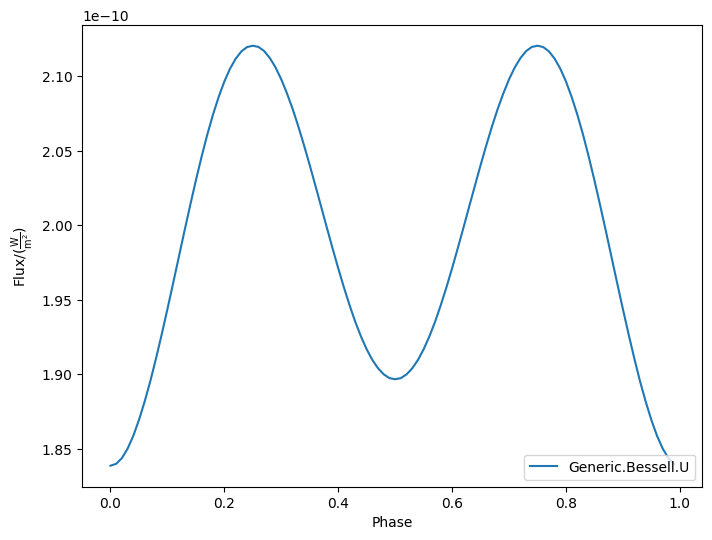

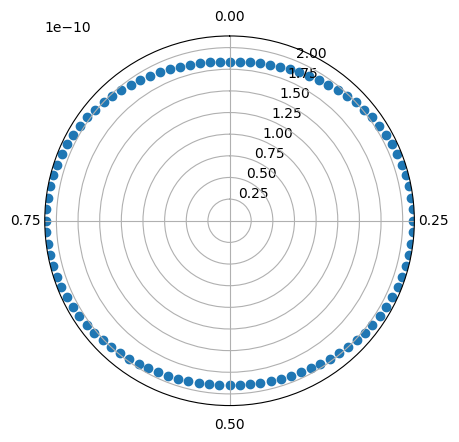

2026-09-23 12:50:36,790 - 11396 - binary_system.system - INFO: initialising object BinarySystem
2026-09-23 12:50:36,842 - 11396 - binary_system.system - INFO: setting discretization factor of secondary component to 8.00 according to discretization factor of the companion.
2026-09-23 12:50:36,843 - 11396 - observer.observer - INFO: initialising Observer instance
2026-09-23 12:50:36,856 - 11396 - observer.observer - INFO: observation is running
2026-09-23 12:50:38,274 - 11396 - binary_system.curves.c_router - INFO: geometry of the stellar surface on one half of the apsidal line will be copied from their closest symmetrical counterparts
Skipping system 1: Limb darkening interpolation lead to numpy.nan/None value. 
Some of the surface parameters (t_eff, log_g, metallicity) are 
probably outside of the supported range. Change the parameters 
of the stars or use your custom ld coefficients that can be passed in 
Star.limb_darkening_coefficients.
2026-09-23 12:50:38,362 - 11396 - binary_syste

KeyboardInterrupt: 

In [33]:
from elisa.base.error import LimbDarkeningError, MorphologyError



phases_range = np.array([])
fluxes_range = np.array([])

for i in range(len(period_range)):
    try:
        primary = Star(
            mass = m1_range[i],
            surface_potential = Omega1_range[i], 
            synchronicity = F1_range[i], 
            t_eff = T1_range[i]
        )
    
        secondary = Star(
            mass = m2_range[i],
            surface_potential = Omega2_range[i],
            synchronicity = F2_range[i],
            t_eff = T2_range[i]
        )
    
        bs = BinarySystem(
            primary=primary,
            secondary=secondary,
            argument_of_periastron = arg_peri_range[i],
            gamma = gamma_range[i],
            period = period_range[i],
            eccentricity = e_range[i],
            inclination = i_range[i],
            primary_minimum_time = 2440000.0000 * u.d, 
            phase_shift = 0,
            distance = dist_range[i]
        )
    
    
        o = Observer(passband=[
    
        'Generic.Bessell.U',
                          ],
                 system=bs)
        
        phases, fluxes = o.observe.lc( # fluxes contains synthetic light curve data for each passband specified in Observer
            from_phase=0,
            to_phase=1,
            phase_step=0.01,
            # normalize=True
        )

        save_dir_data = os.path.join(cwd, "Data\ELISa lightcurve data")

        data = np.column_stack([phases] + list(fluxes.values()))
        header = "phase," + ",".join(fluxes.keys())
        np.savetxt(os.path.join(save_dir_data, f"{i} lightcurve.csv"), data, delimiter=",", header=header, comments="")

        phases_range = np.append(phases_range,phases)
        fluxes_range = np.append(fluxes_range,fluxes)
        
        save_dir = os.path.join(cwd, "Data\ELISa plots")
        
        print(f"System {i}:")
        lc_fig = o.plot.phase_curve(phases=phases, fluxes=fluxes, return_figure_instance=True)
        lc_fig.savefig(os.path.join(save_dir, f"{i} lightcurve.png"))
        plt.show()

        fig = plt.figure()
        theta=2*np.pi*phases # angle 0-2pi
        
        ax = fig.add_subplot(projection='polar')
        tick_locs = np.linspace(0, 2*np.pi, 4, endpoint=False)
        tick_labels = [f"{p:.2f}" for p in np.linspace(0, 1, 4, endpoint=False)] # this and line above help the polar axis to be in phase units, not degrees
        ax.scatter(theta,fluxes['Generic.Bessell.U']) 
        ax.set_xticks(tick_locs)
        ax.set_theta_zero_location('N')
        ax.set_theta_direction(-1)
        ax.set_xticklabels(tick_labels)
        plt.show()
        fig.savefig(os.path.join(save_dir, f"{i} radial_plot.png"))
        
    except (LimbDarkeningError, MorphologyError) as e: # skip sample if ever it is unphysical with regards to log_g
        print(f"Skipping system {i}: {e}")
        continue


In [ ]:
fig = plt.figure()
theta=2*np.pi*phases # phases 0-1 -> angle 0-2pi

ax = fig.add_subplot(projection='polar')
ax.scatter(theta,fluxes['Generic.Bessell.U'])
plt.show()

In [ ]:
print(fluxes)
#print(fluxes_range.shape,fluxes_range)

copy of what i did before the new method, in case a copy is needed. this cell is ultimately to be ignored

for i in range(500):
    m1_kg = random.uniform(0.2*solM,5*solM)
    q = random.uniform(0.1,1) # mass ratio m2/m1
    m2_kg = q * m1_kg
    m1 = m1_kg/(solM) # in solar masses
    m2 = m2_kg/(solM)
    m1_range.append(m1)
    m2_range.append(m2)
    
    gamma=np.random.uniform(15,75) * u.km / u.s
    gamma_range.append(gamma)

    inc=np.random.uniform(50,90) * u.deg # range of i=50 to i=90 degrees, as given in section 7.2.4 in handbook
    inc_range.append(inc)

    dist=np.random.uniform(50,200) * u.pc 
    dist_range.append(dist)
    
    r1 = m1**0.8 if m1 < 1 else m1**0.57  # in solar radii
    r2 = m2**0.8 if m2 < 1 else m2**0.57  # using stellar mass to radius relation

    t1 = (m1_kg)**0.5 
    t2 = (m2_kg)**0.5 # from mass-luminosity relation, into stefan-boltzmann
    t1_range.append(t1)
    t2_range.append(t2)

    arg_peri = np.random.uniform(0,360) # can be anything from 0 to 360 deg, as given by the handbook when testing in sec 7.2.4.
    arg_peri_range.append(arg_peri)

    q_inv = 1/q # Eggleton uses q = m1/m2, we use q = m2/m1
    # approximating Roche Lobe Radius as a sphere, using Eggleton 1983:
    r_L1 = (0.49*q_inv**(2/3))/(0.6*q_inv**(2/3) + np.log(1+q_inv**(1/3))) # normalised by semi-major axis, i think
    # r_L1. If r_1 < r_L1, then it is detached
    # if r_1 = r_L1, it is semidetached
    # if r_1 > r_L1, it is overcontact (i.e. the star has exceeded its Roche lobe)
    

    type = np.random.randint(1,4) # determines if system is detached, semi-detached or contact

    if type == 1: # detached
        a_max = (r1 * solR) / (0.1*r_L1) # prevents the a-normalised radius from being too tiny
        # star's normalised radius must fit at least 10% of the Roche lobe
    
        a_min = (r1*solR+r2*solR)/(0.95*(1-e)) # prevents stars from physically colliding at periastron
        # both stars' combined radius cannot be greater than 95% of the distance between star centres at periastron
    
        if a_min > a_max:
            continue
        
        a = np.random.uniform(a_min,a_max) # randomly sample semi-major axis within boundaries
        period = ((4*np.pi**2)/constants.G * (m1+m2) * a**3)**(0.5)
        period_range.append(period)
        
        e = random.uniform(0.0,0.5) # eccentricity
        e_range.append(e)
    
        F_theory = (1 + e)**2 / (1 - e**2)**(3/2) # theoretically, F_1 and F_2 are the same
    
        # sampling synchronicity with small scatter
        F_1 = np.random.normal(F_theory,0.05)
        F_2 = np.random.normal(F_theory,0.05)
        F1_range.append(F_1)
        F2_range.append(F_2)
        
        #d_min = 1 - e # periastron distance (closest point in orbit to centre of mass), in unitless distance normalised to semi-major axis
        #d_max = 1 + e # apastron distance (furthest point from centre of mass)
    
        d = 1 # calculating surface potential at normalised distance = 1
    
        rho_1 = r1*solR / a
        rho_2 = r2*solR / a # radii normalised by semi-major axis
    
        Omega1 = 1/rho_1 + q*(1/(d - rho_1) - rho_1/(d)**2) + 1/2 * F_1**2 *(1+q)*rho_1**2
        # under same conditions as omega1; d=1, lambda=1, theta=0. Using rho_2 instead of rho_1 Following equation (8) in elisa handbook:
        Omega2 = q/rho_2 + 1/(d**2 - 2*d*rho_2 + rho_2**2)**(0.5) - rho_2/d**2 + 0.5*F_2**2 * (q+1)*rho_2**2 + 0.5*(1-q)
        Omega1_range.append(Omega1)
        Omega2_range.append(Omega2)

    elif type==2: # semi-detached
        
        e = np.random.uniform(0,0.1) # semi-detached systems would have low eccentricities
        e_range.append(e)

        F_theory = (1 + e)**2 / (1 - e**2)**(3/2) 
        F_1 = np.random.normal(F_theory,0.05)
        F_2 = np.random.normal(F_theory,0.05)
        F1_range.append(F_1)
        F2_range.append(F_2)
        
        rho_1 = r_L1 # primary radius fits exactly within Roche lobe

        d=1
        Omega1 = 1/rho_1 + q*(1/(d - rho_1) - rho_1/(d)**2) + 1/2 * F_1**2 *(1+q)*rho_1**2
        Omega2 = q/rho_2 + 1/(d**2 - 2*d*rho_2 + rho_2**2)**(0.5) - rho_2/d**2 + 0.5*F_2**2 * (q+1)*rho_2**2 + 0.5*(1-q)
        Omega1_range.append(Omega1)
        Omega2_range.append(Omega2)
        
        # a = ??
        period = ((4*np.pi**2)/constants.G * (m1+m2) * a**3)**(0.5)
        period_range.append(period)
    else: # overcontact

        e=0 # close binary orbits tend to circular orbits (Zahn 1975)
        e_range.append(e)
        F_1 = F_2 = 1 # close binary stars synchronise fast; on a scale much shorter than nuclear (Zahn 1977)
        F1_range.append(F_1)
        F2_range.append(F_2)
        # here Omega_1 lies between Omega_L1 and Omega_L2
        #Omega_L1 = 1/r_L1 + q*(1/(d - r_L1) - r_L1/(d)**2) + 1/2 * F_1**2 *(1+q)*r_L1**2
        
        # using scipy root finding method to calculate Omega_L2:
        #Omega_L2_1st_deriv = lambda r: -1/r**2 - q/(r-1)**2 - q + (1+q)*r # the first derivative of Omega_L2, with respect to r
        #r_L2 = root_scalar(Omega_L2_1st_deriv, bracket=[1.00001,3.0]).root # search for root. lower bound of 1 orbital separation, upper of 3 orbital separations.
        #Omega_L2 = 1/r_L2 + q*(1/(d - r_L2) - r_L2/(d)**2) + 1/2 * F_1**2 *(1+q)*r_L2**2 # plugs the root back into the equation for Omega, with e=0 and F=1

        #Omega_1 = np.random.uniform(Omega_L1,Omega_L2)

        #a = ??
        period = ((4*np.pi**2)/constants.G * (m1+m2) * a**3)**(0.5)
        period_range.append(period)
        
        Omega1 = 1/rho_1 + q*(1/(d - rho_1) - rho_1/(d)**2) + 1/2 * F_1**2 *(1+q)*rho_1**2
        Omega2 = q/rho_2 + 1/(d**2 - 2*d*rho_2 + rho_2**2)**(0.5) - rho_2/d**2 + 0.5*F_2**2 * (q+1)*rho_2**2 + 0.5*(1-q)
        Omega1_range.append(Omega1)
        Omega2_range.append(Omega2)